In [1]:
import lamindb as ln
import mudata as mu
assert ln.setup.settings.instance.slug == "theislab/sc-best-practices"
ln.track()

→ connected lamindb: theislab/sc-best-practices
! It looks like you are running jupyter lab but don't have jupyter-server module installed. Please install it via pip install jupyter-server
→ created Transform('qMeG9ZuD63Mx0000', key='comparative_cell_cell_comm.ipynb'), started new Run('KK5xPD3A9bWYP7is') at 2026-11-11 09:56:21 UTC
→ notebook imports: lamindb-core==2.10.0 mudata==0.4.1
• tip: to identify the notebook across renames, pass the uid: ln.track("qMeG9ZuD63Mx")


In [2]:
# from urllib.request import urlretrieve
# urlretrieve("https://zenodo.org/records/15756745/files/data_vt3.zip?download=1", "data_vt3.zip")

In [3]:
#! unzip data_vt3.zip#

In [4]:
adata=mu.read_h5mu("data_vt3/second/nichesphere/2306_HMI_allmodalities.h5mu")

/home/james/miniconda3/envs/cellcell/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)


In [5]:
adata.mod['sc'].write_h5ad("comparative_cell_cell_comm.h5ad")

In [6]:
af = ln.Artifact(
    "comparative_cell_cell_comm.h5ad",
    key="conditions/comparative_cell_cell_comm.h5ad",
    description="Kuppe 2022 dataset in h5ad format for the comparative cell cell analysis chapter",
).save()
af

... uploading comparative_cell_cell_comm.h5ad: 100.0%


Artifact(uid='ztiAcBv7iFnHWrZP0000', key='conditions/comparative_cell_cell_comm.h5ad', description='Kuppe 2022 dataset in h5ad format for the comparative cell cell analysis chapter', suffix='.h5ad', kind=None, otype='AnnData', size=1246224147, hash='uu3zIOHmTMAANg7OFFoylh', n_files=None, n_observations=None, extra_data=None, branch_id=1, created_on_id=1, space_id=1, storage_id=1, run_id=229, schema_id=None, created_by_id=14, created_at=2026-11-11 09:56:39 UTC, is_locked=False, version_tag=None, is_latest=True)

In [7]:
ln.finish()

! It looks like you are running jupyter lab but don't have jupyter-server module installed. Please install it via pip install jupyter-server
• please hit CTRL + s to save the notebook in your editor ... ✓
→ finished Run('KK5xPD3A9bWYP7is') after 41s at 2026-11-11 09:57:02 UTC
→ go to: https://lamin.ai/theislab/sc-best-practices/run/KK5xPD3A9bWYP7is
→ to update your notebook from the CLI, run: lamin save /home/james/theis/single-cell-best-practices/scripts/conditions/comparative_cell_cell_comm.ipynb


In [8]:
adata = ln.Artifact.get(
    key="conditions/comparative_cell_cell_comm.h5ad"
).load()
adata

! run input wasn't tracked, call `ln.track()` and re-run


AnnData object with n_obs × n_vars = 48547 × 27416
    obs: 'orig_ident', 'nCount_RNA', 'nFeature_RNA', 'percent_mt', 'doublet_score', 'doublet', 'dissociation_s1', 'opt_clust', 'patient', 'batch', 'opt_clust_integrated', 'cell_type', 'ident', 'nFeaturess_RNA', 'cell_subtype2', 'patient_region_id', 'sampleType'
    var: 'n_counts'
    obsm: 'X_harmony', 'X_pca', 'X_umap_harmony'
    layers: None (.X)

In [9]:
import scanpy as sc

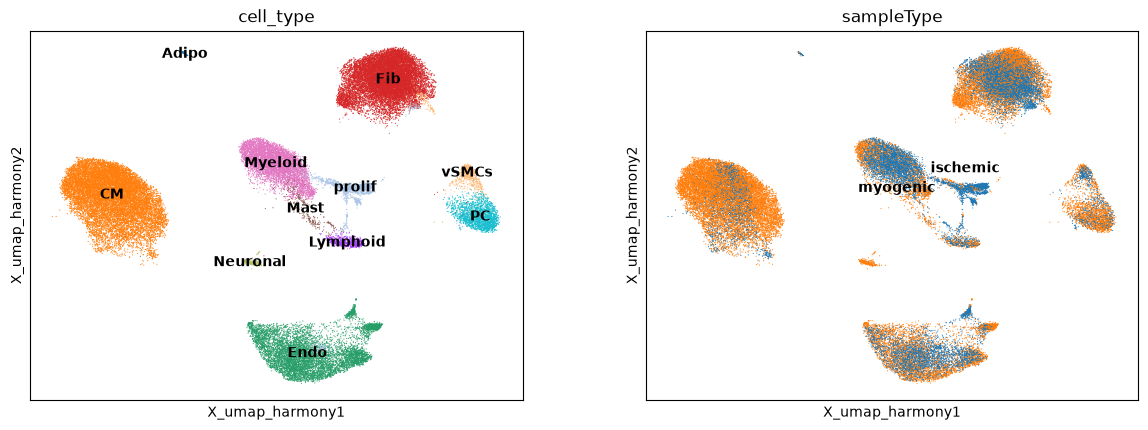

In [12]:
sc.pl.embedding(adata, basis="X_umap_harmony", color=['cell_type',"sampleType"],legend_loc="on data")